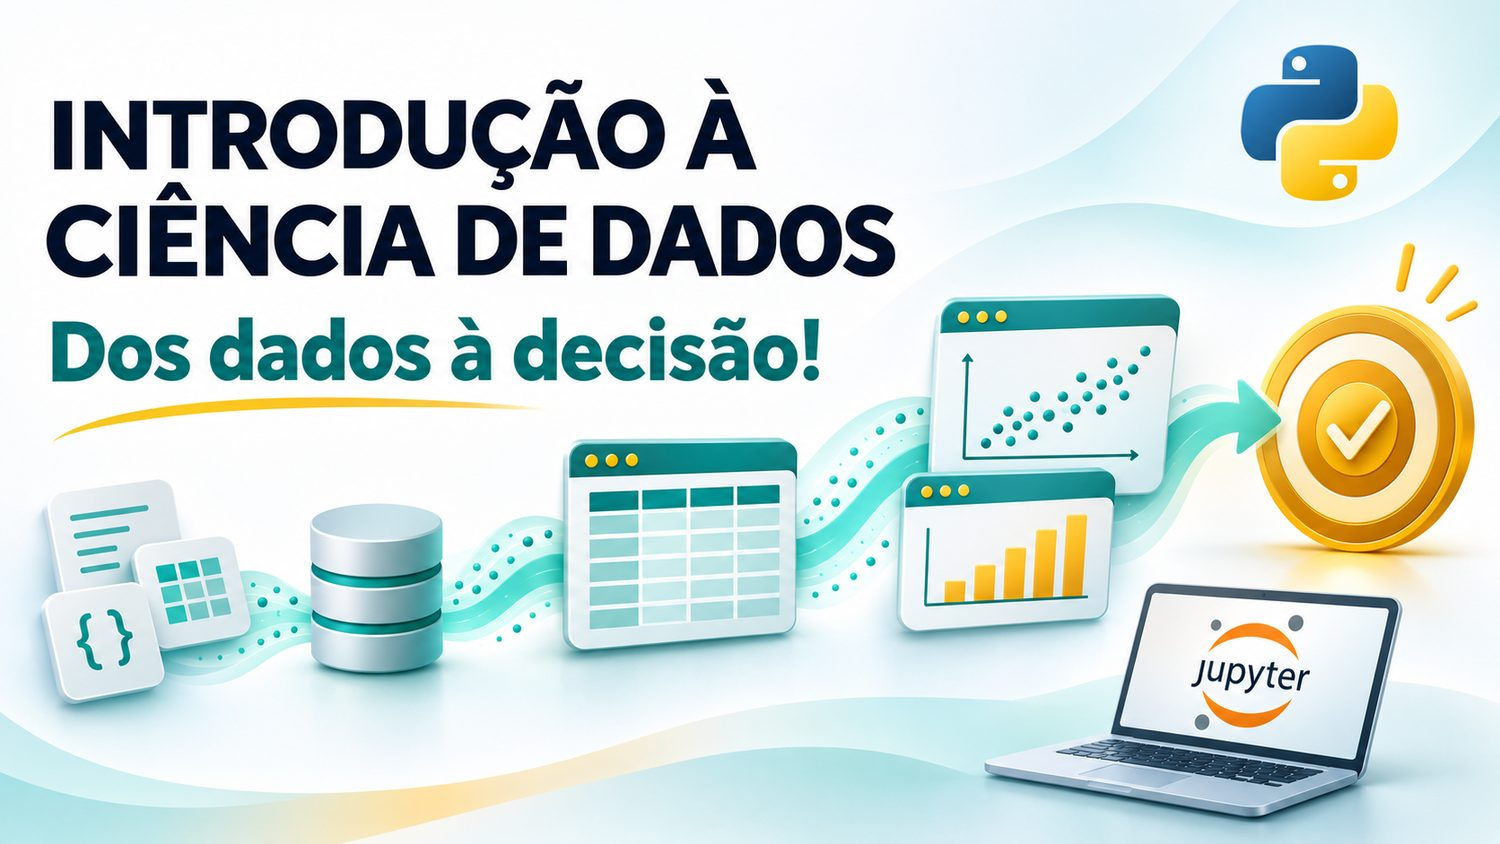

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_2_fontes_tipos_estruturas/02_Tipos_de_Dados.ipynb)

# Capítulo 2 – Tipos de dados: o que significam os valores

Chega um ficheiro com o valor `0043`. É uma quantidade, um identificador ou uma categoria? A resposta decide que contas fazem sentido, e o computador não a sabe dar: limita-se a guardar o que lhe mandarem. Este capítulo ensina a ler o significado de uma variável antes de calcular com ela.

> **Objetivos:** distinguir variáveis numéricas (discretas e contínuas) e categóricas (nominais e ordinais); saber que operações são válidas em cada tipo; separar o significado de uma variável da forma como está guardada; reconhecer armadilhas com identificadores, unidades, datas e valores em falta.

**Pré-requisitos:** capítulo 1 deste módulo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_padaria(semente=7):
    """Gera os dados de uma cadeia fictícia de padarias (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    lojas = pd.DataFrame({
        "loja_id": ["0041", "0042", "0043", "0107", "0212", "0305"],
        "zona": ["Baixa", "Baixa", "Ribeira", "Estação", "Universidade", "Mercado"],
        "producao_habitual": [320, 260, 180, 400, 220, 300]})
    dias = pd.date_range("2026-03-02", periods=84, freq="D")          # doze semanas, de segunda a domingo
    chuva = np.where(rng.random(84) < 0.35, rng.gamma(2.0, 3.0, 84).round(1), 0.0)
    meteo = pd.DataFrame({"data": dias, "chuva_mm": chuva})
    eventos = pd.DataFrame({
        "data": pd.to_datetime(["2026-03-14", "2026-03-28", "2026-04-11", "2026-04-25", "2026-05-09", "2026-05-16"]),
        "zona": ["Ribeira", "Mercado", "Baixa", "Baixa", "Ribeira", "Universidade"],
        "evento": ["Feira do livro", "Mercado de produtores", "Maratona", "Desfile", "Festival de rua", "Dia aberto"]})
    fator_dia = [0.95, 0.90, 0.92, 0.97, 1.06, 1.20, 1.08]            # segunda a domingo
    linhas = []
    for loja in lojas.itertuples():
        for dia, mm in zip(dias, chuva):
            ha_evento = ((eventos["data"] == dia) & (eventos["zona"] == loja.zona)).any()
            procura = (loja.producao_habitual * 0.9 * fator_dia[dia.dayofweek] * (1 - 0.012 * mm)
                       * (1.35 if ha_evento else 1.0) * rng.normal(1.0, 0.07))
            linhas.append((loja.loja_id, dia, loja.producao_habitual, int(min(round(procura), loja.producao_habitual))))
    vendas = pd.DataFrame(linhas, columns=["loja_id", "data", "produzidos", "vendidos"])
    return lojas, vendas, meteo, eventos


lojas, vendas, meteo, eventos = gerar_padaria()
vendas.head()

,loja_id,data,produzidos,vendidos
0,0041,2026-03-02,320,260
1,0041,2026-03-03,320,250
2,0041,2026-03-04,320,290
3,0041,2026-03-05,320,253
4,0041,2026-03-06,320,253


## Dois grandes tipos, quatro subtipos

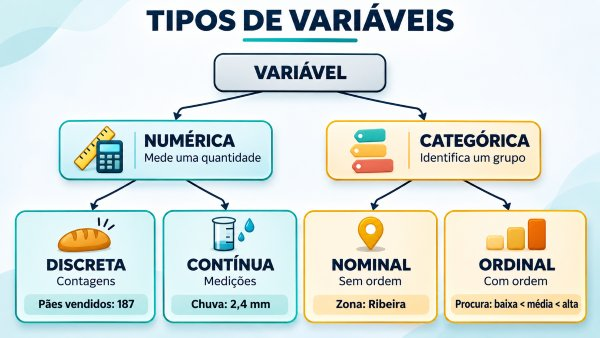

- Uma variável **numérica** mede uma quantidade. As operações aritméticas têm significado: faz sentido somar pães e calcular a chuva média.
  - **Discreta:** resulta de uma contagem; só toma certos valores (0, 1, 2…).
  - **Contínua:** resulta de uma medição; pode tomar qualquer valor num intervalo.
- Uma variável **categórica** identifica um grupo. A aritmética não tem significado.
  - **Nominal:** as categorias não têm ordem (zonas, nomes de lojas).
  - **Ordinal:** as categorias têm ordem, mas a distância entre elas não é conhecida (procura baixa, média e alta).

### Que operações são válidas em cada tipo

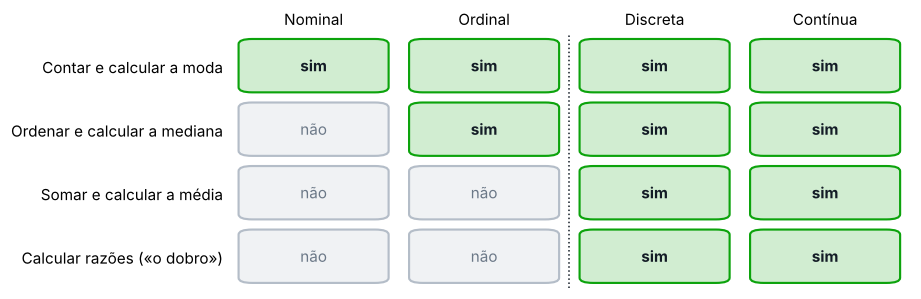

In [3]:
operacoes = ["Contar e calcular a moda", "Ordenar e calcular a mediana", "Somar e calcular a média", "Calcular razões («o dobro»)"]
tipos = ["Nominal", "Ordinal", "Discreta", "Contínua"]
valida = np.array([[1, 1, 1, 1], [0, 1, 1, 1], [0, 0, 1, 1], [0, 0, 1, 1]])

fig, ax = plt.subplots(figsize=(8, 3))
for i in range(4):
    for j in range(4):
        cor = BOM if valida[i, j] else CINZA
        ax.add_patch(FancyBboxPatch((j + 0.06, 3 - i + 0.08), 0.88, 0.84, boxstyle="round,pad=0,rounding_size=0.08",
                                    fc=cor + "30", ec=cor, lw=1.4))
        ax.text(j + 0.5, 3 - i + 0.5, "sim" if valida[i, j] else "não", ha="center", va="center",
                fontweight="bold" if valida[i, j] else "normal", color=TINTA if valida[i, j] else "#6b7887")
ax.set_xlim(0, 4)
ax.set_ylim(0, 4)
ax.set_xticks(np.arange(4) + 0.5, tipos)
ax.set_yticks(np.arange(4) + 0.5, operacoes[::-1])
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.axvline(2, color=TINTA, lw=1, ls=":")
plt.show()

A tabela lê-se como uma escada: cada tipo permite tudo o que o anterior permite e mais alguma coisa. Calcular a média de uma variável ordinal (por exemplo, a média de «baixa, média, alta» codificadas como 1, 2, 3) é um erro frequente: pressupõe que a distância entre «baixa» e «média» é igual à distância entre «média» e «alta», e ninguém garantiu isso.

## Significado e armazenamento são coisas diferentes

Cada variável tem duas propriedades independentes:

- o **significado**: o que representa (uma quantidade, uma categoria, um instante, um local);
- o **armazenamento**: como está guardada no computador (texto, número inteiro, número decimal, booleano, data e hora).

O pandas só conhece a segunda.

In [4]:
vendas.dtypes

loja_id                  str
data          datetime64[us]
produzidos             int64
vendidos               int64
dtype: object

| Coluna | Armazenamento | Significado |
| --- | --- | --- |
| `loja_id` | texto | categórica nominal (um identificador) |
| `data` | data e hora | um instante |
| `produzidos` | inteiro | numérica discreta |
| `vendidos` | inteiro | numérica discreta |

O problema aparece quando as duas propriedades não coincidem.

### Um número que não é uma quantidade

O identificador das lojas é formado por algarismos. Vamos gravar a tabela num ficheiro CSV e voltar a lê-la, como aconteceria num projeto real.

In [5]:
import io

ficheiro = vendas.head(4).to_csv(index=False)
print(ficheiro)

lido = pd.read_csv(io.StringIO(ficheiro))
print(lido.dtypes, "\n")
print(lido)

loja_id,data,produzidos,vendidos
0041,2026-03-02,320,260
0041,2026-03-03,320,250
0041,2026-03-04,320,290
0041,2026-03-05,320,253

loja_id       int64
data            str
produzidos    int64
vendidos      int64
dtype: object 

   loja_id        data  produzidos  vendidos
0       41  2026-03-02         320       260
1       41  2026-03-03         320       250
2       41  2026-03-04         320       290
3       41  2026-03-05         320       253


Aconteceram duas coisas sem qualquer aviso:

1. `loja_id` passou a ser um número inteiro e **perdeu os zeros à esquerda**: `"0041"` tornou-se `41`.
2. `data` passou a ser texto.

O pandas viu algarismos e concluiu que era uma quantidade. As consequências aparecem mais tarde.

In [6]:
print("«Loja média»:", lido["loja_id"].mean())                       # uma conta sem significado
juncao = lido.astype({"loja_id": str}).merge(lojas, on="loja_id", how="left")
print("Linhas sem zona depois de juntar com o cadastro:", int(juncao["zona"].isna().sum()), "de", len(juncao))

«Loja média»: 41.0
Linhas sem zona depois de juntar com o cadastro: 4 de 4


A média dos identificadores calcula-se sem erro e não significa nada. E a junção com o cadastro falha em **todas** as linhas, porque `"41"` e `"0041"` são textos diferentes. O programa não avisa: as colunas novas ficam simplesmente vazias.

A solução é dizer ao pandas o que cada coluna significa no momento da leitura.

In [7]:
lido = pd.read_csv(io.StringIO(ficheiro), dtype={"loja_id": str}, parse_dates=["data"])
print(lido.dtypes, "\n")
print(lido.merge(lojas, on="loja_id", how="left")[["loja_id", "data", "zona"]])

loja_id                  str
data          datetime64[us]
produzidos             int64
vendidos               int64
dtype: object 

  loja_id       data   zona
0    0041 2026-03-02  Baixa
1    0041 2026-03-03  Baixa
2    0041 2026-03-04  Baixa
3    0041 2026-03-05  Baixa


> **Um valor que parece numérico pode ser um identificador.** Códigos postais, números de telefone, números de contribuinte, códigos de produto e identificadores de lojas são categorias escritas com algarismos. Guardam-se como texto.

Um teste simples: **faz sentido somar dois destes valores?** Se não fizer, a variável não é numérica.

### Uma ordem que o computador não conhece

Vamos classificar a procura de cada dia em três níveis, conforme a fração da produção que se vendeu.

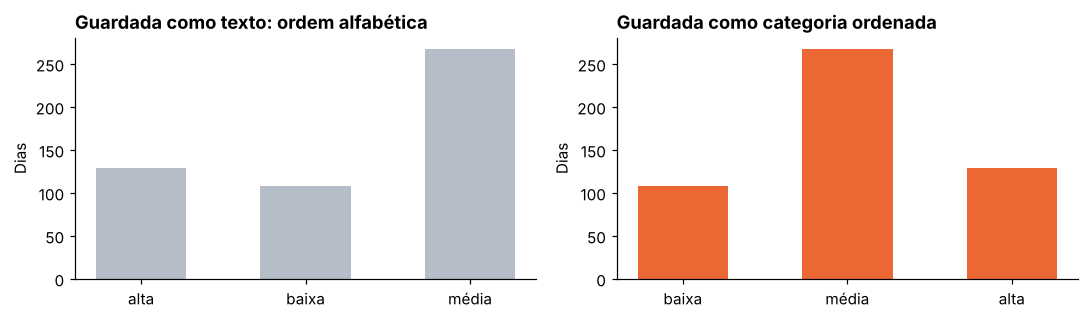

Procura mediana: média
Dias com procura acima de «baixa»: 396


In [8]:
fracao = vendas["vendidos"] / vendas["produzidos"]
vendas["procura"] = pd.cut(fracao, [0, 0.8, 0.95, 1.0], labels=["baixa", "média", "alta"]).astype(str)

como_texto = vendas["procura"].value_counts().sort_index()
niveis = pd.CategoricalDtype(["baixa", "média", "alta"], ordered=True)
vendas["procura"] = vendas["procura"].astype(niveis)
como_ordinal = vendas["procura"].value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
ax1.bar(como_texto.index, como_texto, color=CINZA, width=0.55)
ax1.set_title("Guardada como texto: ordem alfabética")
ax2.bar(como_ordinal.index.astype(str), como_ordinal, color=LARANJA, width=0.55)
ax2.set_title("Guardada como categoria ordenada")
for eixo in (ax1, ax2):
    eixo.set_ylabel("Dias")
plt.tight_layout()
plt.show()

print("Procura mediana:", vendas["procura"].sort_values().iloc[len(vendas) // 2])
print("Dias com procura acima de «baixa»:", int((vendas["procura"] > "baixa").sum()))

Guardada como texto, a variável é ordenada alfabeticamente («alta, baixa, média»), e os gráficos e as tabelas saem numa ordem sem sentido. Depois de declarar a ordem, o pandas sabe ordenar, comparar e calcular a mediana.

## Unidades

Um número sem unidade é metade de um dado. A loja `0107` muda de sistema de caixa a meio do período e passa a comunicar as vendas em **dúzias**. Ninguém avisa.

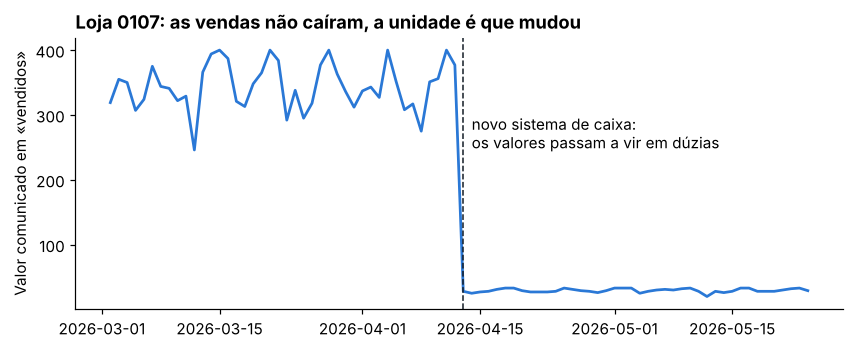

Média comunicada antes: 344
Média comunicada depois: 29


In [9]:
loja = vendas[vendas["loja_id"] == "0107"].copy()
mudanca = pd.Timestamp("2026-04-13")
loja["comunicado"] = np.where(loja["data"] >= mudanca, (loja["vendidos"] / 12).round(), loja["vendidos"])

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(loja["data"], loja["comunicado"], color=AZUL, lw=1.8)
ax.axvline(mudanca, color=TINTA, ls="--", lw=1)
ax.text(mudanca + pd.Timedelta(days=1), 300, "novo sistema de caixa:\nos valores passam a vir em dúzias", va="top")
ax.set_ylabel("Valor comunicado em «vendidos»")
ax.set_title("Loja 0107: as vendas não caíram, a unidade é que mudou")
plt.show()

print(f"Média comunicada antes: {loja.loc[loja['data'] < mudanca, 'comunicado'].mean():.0f}")
print(f"Média comunicada depois: {loja.loc[loja['data'] >= mudanca, 'comunicado'].mean():.0f}")

Quem olhar só para os números conclui que a loja perdeu mais de 90% das vendas. Um modelo treinado com esta coluna aprenderia que a loja quase não vende pão.

Sinais de que há um problema de unidades:

- uma mudança brusca numa data precisa;
- valores que diferem por um fator «redondo» (12, 100, 1 000, 1,609, 2,54);
- uma fonte com valores numa escala muito diferente das outras.

A defesa é pôr a unidade no **nome da coluna** (`chuva_mm`, `peso_kg`, `preco_eur`) e confirmá-la na documentação de cada fonte.

## Datas e horas

Uma data escrita como texto pode querer dizer várias coisas.

In [10]:
texto = "01/02/26"
leituras = {"dia/mês/ano (Portugal)": pd.to_datetime(texto, format="%d/%m/%y"),
            "mês/dia/ano (EUA)": pd.to_datetime(texto, format="%m/%d/%y"),
            "ano/mês/dia": pd.to_datetime(texto, format="%y/%m/%d")}
for convencao, data in leituras.items():
    print(f"{convencao:<24} → {data.date()}  ({data.day_name()})")

dia/mês/ano (Portugal)   → 2026-02-01  (Sunday)
mês/dia/ano (EUA)        → 2026-01-02  (Friday)
ano/mês/dia              → 2001-02-26  (Monday)


O mesmo texto dá três datas, em três dias da semana diferentes. Num problema em que o dia da semana é a variável mais importante, a convenção errada estraga o conjunto de dados inteiro, e nenhum programa dá erro.

As horas têm um problema parecido: o **fuso horário**. Um sistema central pode registar tudo em tempo universal (UTC), enquanto as lojas funcionam na hora local.

In [11]:
for dia in ["2026-01-15 07:30", "2026-07-15 07:30"]:
    abertura = pd.Timestamp(dia, tz="Europe/Lisbon")
    print(f"Abertura às {abertura.strftime('%H:%M')} em Lisboa, a {abertura.strftime('%d/%m')}  →  "
          f"{abertura.tz_convert('UTC').strftime('%H:%M')} UTC")

Abertura às 07:30 em Lisboa, a 15/01  →  07:30 UTC
Abertura às 07:30 em Lisboa, a 15/07  →  06:30 UTC


No inverno as duas horas coincidem; no verão diferem uma hora. Se os registos estiverem em UTC e ninguém o souber, as vendas da primeira hora do dia aparecem deslocadas durante metade do ano.

> **Regras práticas:** guarda datas no formato ISO 8601 (`2026-02-01`), que não tem ambiguidade; indica sempre o formato ao ler datas escritas de outra forma; regista o fuso horário de cada fonte.

## Valores em falta não são zeros

Imagina dois casos: uma loja que fecha ao domingo, e a loja `0043` num dia em que a caixa avariou e não registou as vendas. Os dois podem aparecer no ficheiro como `0`, mas não querem dizer o mesmo:

- loja fechada: **sabemos** que se venderam zero pães;
- caixa avariada: **não sabemos** quantos pães se venderam.

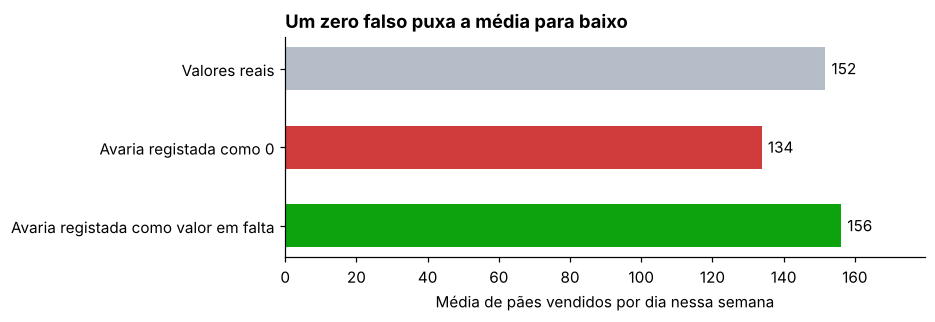

,data,vendidos,avaria_como_zero,avaria_como_falta
168,2026-03-02,171,171,171.0
169,2026-03-03,139,139,139.0
170,2026-03-04,151,151,151.0
171,2026-03-05,125,0,NaN
172,2026-03-06,151,151,151.0
173,2026-03-07,180,180,180.0
174,2026-03-08,145,145,145.0


In [12]:
semana = vendas[(vendas["loja_id"] == "0043") & (vendas["data"] < "2026-03-09")][["data", "vendidos"]].copy()
semana["avaria_como_zero"] = semana["vendidos"].where(semana["data"] != "2026-03-05", 0)
semana["avaria_como_falta"] = semana["vendidos"].where(semana["data"] != "2026-03-05", np.nan)

medias = semana[["vendidos", "avaria_como_zero", "avaria_como_falta"]].mean()
fig, ax = plt.subplots(figsize=(7.5, 2.6))
barras = ax.barh(["Valores reais", "Avaria registada como 0", "Avaria registada como valor em falta"], medias,
                 color=[CINZA, MAU, BOM], height=0.55)
ax.bar_label(barras, fmt="%.0f", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, medias.max() * 1.15)
ax.set_xlabel("Média de pães vendidos por dia nessa semana")
ax.set_title("Um zero falso puxa a média para baixo")
plt.show()

semana

Com o zero falso, a média semanal desce de 152 para 134 pães. Com o valor em falta (`NaN`), o pandas ignora esse dia e a média fica próxima da verdadeira.

Um valor em falta pode chegar disfarçado de muitas formas: uma célula vazia, `0`, `-1`, `999`, `"N/D"`, `"-"`. Cabe a quem analisa descobrir qual é a convenção de cada fonte.

> **«Não sei» e «zero» são respostas diferentes.** Antes de calcular, descobre como é que cada fonte representa o que não sabe.

## Resumo: compreender antes de calcular

| Passo | Pergunta | Exemplo |
| --- | --- | --- |
| 1. Significado | O que representa esta variável? Que operações fazem sentido? | `loja_id` é uma categoria: não se soma |
| 2. Armazenamento | O tipo guardado corresponde ao significado? | `loja_id` deve ser texto, e não inteiro |
| 3. Unidades | Em que unidade está, e é a mesma em todas as fontes? | pães ou dúzias |
| 4. Datas | Que convenção e que fuso horário? | `01/02/26` é 1 de fevereiro |
| 5. Valores em falta | Como se representa «não sei»? | `0` pode ser uma avaria |

## Exercícios

### `Exercício 1` – Que tipo de variável é?

Classifica cada variável (nominal, ordinal, discreta ou contínua) e indica como a guardarias:

1. Código postal de cada loja (por exemplo, `4000-123`).
2. Número de empregados por turno.
3. Temperatura do forno, em graus Celsius.
4. Avaliação dos clientes: «má», «razoável», «boa», «excelente».
5. Número de telefone da loja.
6. Peso de farinha gasto por dia, em quilogramas.
7. Tipo de pão: «trigo», «centeio», «mistura».

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Nominal; texto.
2. Discreta; inteiro.
3. Contínua; decimal.
4. Ordinal; categoria ordenada.
5. Nominal; texto (ninguém soma números de telefone, e podem começar por `0` ou por `+`).
6. Contínua; decimal.
7. Nominal; texto ou categoria.

</details>

### `Exercício 2` – A média que não devia existir

Um relatório indica que «a avaliação média das lojas é 2,7», tendo codificado má = 1, razoável = 2, boa = 3 e excelente = 4. O que está errado e o que apresentarias em vez disso?

<details>
<summary><b>Ver uma solução possível</b></summary>

A avaliação é ordinal. A média pressupõe que a distância entre «má» e «razoável» é igual à distância entre «boa» e «excelente», o que ninguém mediu. Uma codificação diferente (por exemplo 0, 1, 3, 10) daria outra média e outra conclusão.

Em vez da média, apresenta-se a distribuição (quantas avaliações em cada nível), a mediana ou a percentagem de avaliações «boa» ou «excelente».

</details>

### `Exercício 3` – Ler um ficheiro com cuidado

O texto abaixo é o conteúdo de um ficheiro recebido de uma loja. Lê-o com `pd.read_csv` de forma que o identificador mantenha os zeros, a data seja interpretada como dia/mês/ano e `N/D` seja tratado como valor em falta.

In [13]:
recebido = """loja_id,data,vendidos
0043,01/02/26,171
0043,02/02/26,N/D
0043,03/02/26,165
"""
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
tabela = pd.read_csv(io.StringIO(recebido), dtype={"loja_id": str}, na_values=["N/D"])
tabela["data"] = pd.to_datetime(tabela["data"], format="%d/%m/%y")
print(tabela.dtypes)
tabela
```

Repara que `vendidos` passa a ser decimal: os inteiros do NumPy não têm forma de representar um valor em falta. Para manter inteiros, usa o tipo `"Int64"` do pandas (com maiúscula).

</details>

### `Exercício 4` – Detetar a mudança de unidade

Usa a tabela `loja` (da secção sobre unidades) para escrever uma verificação automática que encontre a data em que a escala dos valores muda. Sugestão: compara cada valor com a mediana dos sete dias anteriores.

In [14]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
anterior = loja["comunicado"].rolling(7).median().shift(1)
razao = loja["comunicado"] / anterior
suspeitos = loja[(razao < 0.2) | (razao > 5)]
print(suspeitos[["data", "comunicado"]].head(3))
```

A primeira data assinalada é 13 de abril. A razão entre o valor desse dia e a mediana anterior é próxima de 1/12, o que aponta para dúzias. A verificação encontra a data; a explicação tem de ser confirmada com a loja.

</details>

## Verifica o que aprendeste

- [ ] Sei distinguir variáveis nominais, ordinais, discretas e contínuas.
- [ ] Sei que operações são válidas em cada tipo.
- [ ] Sei distinguir o significado de uma variável da forma como está guardada.
- [ ] Sei porque um identificador se guarda como texto, e como o ler corretamente.
- [ ] Sei reconhecer sinais de unidades misturadas.
- [ ] Sei porque `01/02/26` é ambíguo e o que fazer.
- [ ] Sei distinguir um zero de um valor em falta.

## Leitura recomendada

- https://en.wikipedia.org/wiki/Level_of_measurement
- https://pandas.pydata.org/docs/user_guide/categorical.html
- https://pandas.pydata.org/docs/user_guide/missing_data.html
- https://en.wikipedia.org/wiki/ISO_8601